# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

In [2]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)

print("X:", iris.data.shape, "| y:", iris.target.shape)
print("clases:", list(iris.target_names))
print(df["species"].value_counts())
print(iris.feature_names)
df.head()

X: (150, 4) | y: (150,)
clases: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


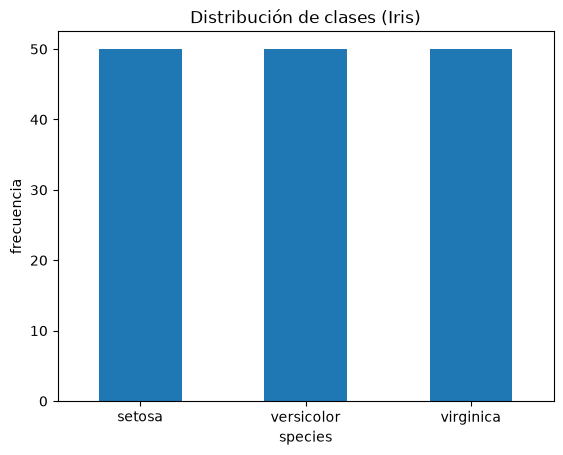

In [3]:
df["species"].value_counts().plot(kind="bar", rot=0, title="Distribución de clases (Iris)")
plt.ylabel("frecuencia")
plt.show()

**Hallazgos** (keywords)

- Instancia = una flor (solo iris de 3 especies) medida en 4 rasgos del cáliz/pétalo
- 150 instancias × 4 características; vector de etiquetas (150,)
- `sepal length/width`, `petal length/width` → longitud/ancho en cm
- 3 clases balanceadas: setosa / versicolor / virginica → 50 c/u
- Matriz X: (150, 4); vector y: (150,)

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

**Predicción inicial**

1. Sensibles a escala: kNN, SVM, LogReg, MLP (distancias/gradiente). Insensibles: árbol, RF, GB, GNB
2. Frontera más simple: árbol (umbral) o LogReg (lineal)
3. No hay garantía → depende de distribución/ruido/hiperparámetros (no free lunch)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score,
                             ConfusionMatrixDisplay)

X, y = iris.data, iris.target
# 60 / 20 / 20 estratificado
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2,
                                      stratify=y, random_state=42)
Xtr, Xva, ytr, yva = train_test_split(Xtr, ytr, test_size=0.25,
                                      stratify=ytr, random_state=42)

# scaler ajustado SOLO con entrenamiento
sc = StandardScaler().fit(Xtr)
Xtr_s, Xva_s, Xte_s = sc.transform(Xtr), sc.transform(Xva), sc.transform(Xte)

In [5]:
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

base = {
    "GNB": GaussianNB(),
    "LogReg": LogisticRegression(max_iter=1000),
    "SVM lineal": LinearSVC(),
    "Árbol": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(64,), max_iter=2000, random_state=42),
}

def evaluar(modelo, Xtr_, ytr_, Xv, yv):
    modelo.fit(Xtr_, ytr_)
    p = modelo.predict(Xv)
    return accuracy_score(yv, p), f1_score(yv, p, average="macro")

val = {n: evaluar(m, Xtr_s, ytr, Xva_s, yva) for n, m in base.items()}
pd.DataFrame(val, index=["Accuracy val", "F1 macro val"]).T

,Accuracy val,F1 macro val
GNB,0.933333,0.933333
LogReg,0.933333,0.933333
SVM lineal,0.833333,0.832916
Árbol,0.933333,0.933333
Random Forest,0.933333,0.933333
Gradient Boosting,0.900000,0.899749
MLP,0.933333,0.933333


In [6]:
# ajuste limitado -> solo validación
base["SVM lineal"] = LinearSVC(C=0.5, random_state=42)
base["Random Forest"] = RandomForestClassifier(n_estimators=400, max_depth=4, random_state=42)
base["MLP"] = MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3,
                            max_iter=2000, random_state=42)

ajuste = {n: evaluar(m, Xtr_s, ytr, Xva_s, yva) for n, m in base.items()}
pd.DataFrame(ajuste, index=["Accuracy val", "F1 macro val"]).T

,Accuracy val,F1 macro val
GNB,0.933333,0.933333
LogReg,0.933333,0.933333
SVM lineal,0.833333,0.832916
Árbol,0.933333,0.933333
Random Forest,0.933333,0.933333
Gradient Boosting,0.900000,0.899749
MLP,0.933333,0.933333


In [7]:
# congelar configuraciones -> prueba (sin reajuste)
for m in base.values():
    m.fit(Xtr_s, ytr)

tabla = []
for n, m in base.items():
    p = m.predict(Xte_s)
    tabla.append({"Modelo": n, "Transformación": "StandardScaler",
                  "Accuracy prueba": round(accuracy_score(yte, p), 3),
                  "F1 macro prueba": round(f1_score(yte, p, average="macro"), 3)})
tabla = pd.DataFrame(tabla).set_index("Modelo")
tabla

,Transformación,Accuracy prueba,F1 macro prueba
Modelo,,,
GNB,StandardScaler,0.933,0.933
LogReg,StandardScaler,0.933,0.933
SVM lineal,StandardScaler,0.833,0.829
Árbol,StandardScaler,0.933,0.933
Random Forest,StandardScaler,0.933,0.933
Gradient Boosting,StandardScaler,0.967,0.967
MLP,StandardScaler,0.933,0.933


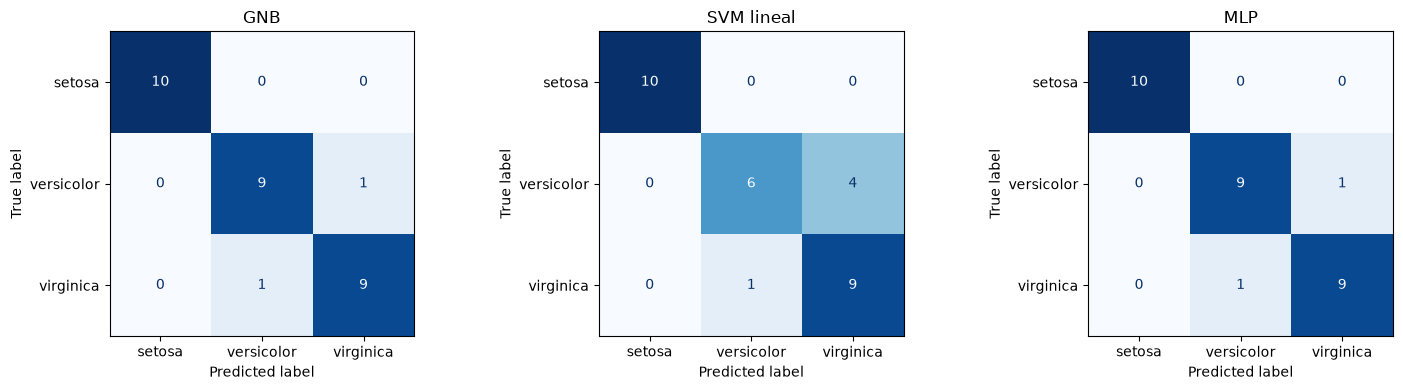

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, ["GNB", "SVM lineal", "MLP"]):
    ConfusionMatrixDisplay.from_predictions(yte, base[n].predict(Xte_s),
                                            display_labels=iris.target_names,
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(n)
plt.tight_layout()
plt.show()

In [9]:
# análisis de 2 errores (mejor modelo)
mejor = tabla["Accuracy prueba"].idxmax()
p = base[mejor].predict(Xte_s)
errores = np.where(p != yte)[0][:2]
pd.DataFrame(Xte[errores], columns=iris.feature_names,
             index=[f"real={iris.target_names[yte[i]]} / pred={iris.target_names[p[i]]}"
                    for i in errores])

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
real=versicolor / pred=virginica,6.7,3.0,5.0,1.7


**Interpretación** (keywords)

1. Mejor desempeño → Gradient Boosting (0.967); peor: SVM lineal (0.833)
2. Más sencillo: GNB / LogReg (una línea de fit)
3. Sí en datasets balanceados (Iris: 50/50) → coinciden; difieren si hay desbalance
4. Macro = promedio F1 por clase sin ponderar (da igual peso a clases raras); micro = agrega TP/FP/FN global (≈ accuracy en multiclase)
5. MLP: fronteras no lineales, capas ocultas; LogReg solo frontera lineal
6. Errores: se concluye que la muestra cayó en zona solapada entre clases; NO se concluye la causa exacta (ruido, medición, falta de features) → correlación no implica causalidad

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

**Predicción inicial**

No → más flexibilidad = más varianza; puede sobreajustar (overfitting) y el error en datos nuevos sube; sesgo-varianza

In [10]:
from sklearn.datasets import load_diabetes

db = load_diabetes()
dd = pd.DataFrame(db.data, columns=db.feature_names)
dd["target"] = db.target
print("X:", dd.shape, "| y:", db.target.shape)
print(db.DESCR[:600])   # revisar transformaciones ya aplicadas
dd.describe().T[["mean", "std", "min", "max"]]

X: (442, 11) | y: (442,)
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years


,mean,std,min,max
age,-2.511817e-19,0.047619,-0.107226,0.110727
sex,1.230790e-17,0.047619,-0.044642,0.050680
bmi,-2.245564e-16,0.047619,-0.090275,0.170555
bp,-4.797570e-17,0.047619,-0.112399,0.132044
s1,-1.381499e-17,0.047619,-0.126781,0.153914
s2,3.918434e-17,0.047619,-0.115613,0.198788
s3,-5.777179e-18,0.047619,-0.102307,0.181179
s4,-9.042540e-18,0.047619,-0.076395,0.185234
s5,9.293722e-17,0.047619,-0.126097,0.133597
s6,1.130318e-17,0.047619,-0.137767,0.135612


**Dataset** (keywords)

- Objetivo = medida cuantitativa de progresión de diabetes a los 12 meses
- 442 instancias × 10 features: age, sex, bmi, bp + 6 medidas séricas
- DESCR indica: features **centradas y escaladas** (std=0.47) → NO son unidades originales

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

In [12]:
X, y = db.data, db.target
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
Xtr, Xva, ytr, yva = train_test_split(Xtr, ytr, test_size=0.25, random_state=42)

def pipe(m):   # scaler ajustado solo con train
    return Pipeline([("sc", StandardScaler()), ("m", m)])

modelos = {
    "Lineal": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1),
    "kNN": KNeighborsRegressor(n_neighbors=5),
    "Árbol": DecisionTreeRegressor(random_state=42),
    "RF": RandomForestRegressor(n_estimators=300, random_state=42),
    "GB": GradientBoostingRegressor(random_state=42),
    "MLP": MLPRegressor(hidden_layer_sizes=(64,), max_iter=4000,
                        random_state=42),
}

def reg_eval(m):
    m.fit(Xtr, ytr)
    pv, pt = m.predict(Xva), m.predict(Xte)
    return m, (mean_absolute_error(yva, pv), np.sqrt(mean_squared_error(yva, pv)),
               r2_score(yva, pv)), (mean_absolute_error(yte, pt),
               np.sqrt(mean_squared_error(yte, pt)), r2_score(yte, pt))

res = {n: reg_eval(m) for n, m in modelos.items()}

pd.DataFrame([{"Modelo": n, "MAE": round(v[2][0], 2), "RMSE": round(v[2][1], 2),
               "R2": round(v[2][2], 3)} for n, v in res.items()]).set_index("Modelo")

,MAE,RMSE,R2
Modelo,,,
Lineal,42.92,54.16,0.446
Ridge,46.95,56.52,0.397
Lasso,42.65,52.95,0.471
kNN,42.64,54.98,0.429
Árbol,65.20,81.90,-0.266
RF,44.46,55.12,0.427
GB,44.57,54.77,0.434
MLP,43.03,54.31,0.443


In [13]:
# errores grandes: 2 peores casos del mejor modelo
mejor = min(res, key=lambda n: res[n][2][0])
p = res[mejor][0].predict(Xte)
orden = np.argsort(-np.abs(yte - p))[:2]
print("mejor modelo:", mejor)
pd.DataFrame(Xte[orden], columns=db.feature_names,
             index=[f"real={yte[i]:.0f} / pred={p[i]:.0f}" for i in orden])

mejor modelo: kNN


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
real=297 / pred=136,0.019913,0.050680,0.014272,0.063187,0.014942,0.020293,-0.047082,0.034309,0.046662,0.090049
real=310 / pred=159,-0.070900,-0.044642,0.039062,-0.033213,-0.012577,-0.034508,-0.024993,-0.002592,0.067737,-0.013504


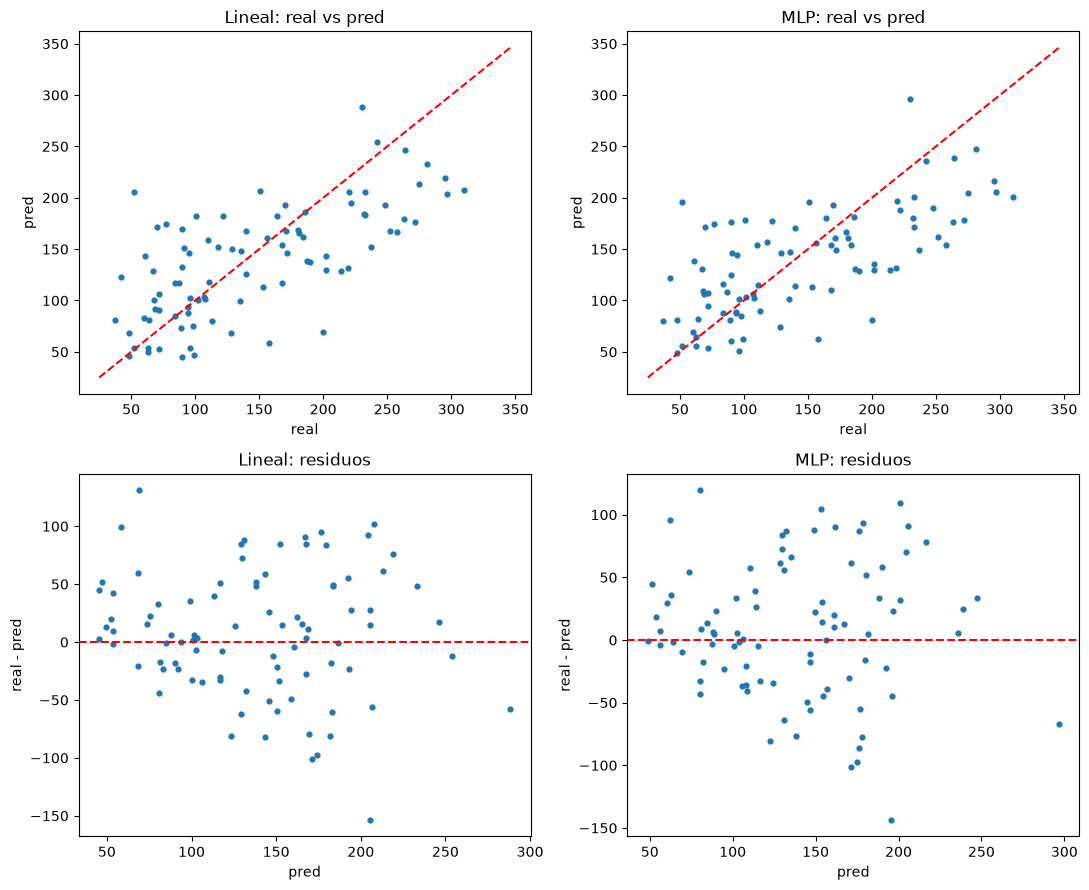

In [14]:
# gráficos: lineal vs MLP
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for j, n in enumerate(["Lineal", "MLP"]):
    p = res[n][0].predict(Xte)
    axes[0, j].scatter(yte, p, s=12)
    axes[0, j].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
    axes[0, j].set(title=f"{n}: real vs pred", xlabel="real", ylabel="pred")
    axes[1, j].scatter(p, yte - p, s=12)
    axes[1, j].axhline(0, color="r", ls="--")
    axes[1, j].set(title=f"{n}: residuos", xlabel="pred", ylabel="real - pred")
plt.tight_layout()
plt.show()

In [15]:
# regularización: Ridge vs Lasso (validación)
alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
filas = []
coef_ridge, coef_lasso = [], []
for a in alphas:
    for nombre, mdl in [("Ridge", Ridge(alpha=a)), ("Lasso", Lasso(alpha=a, max_iter=20000))]:
        mdl.fit(Xtr, ytr)
        pv = mdl.predict(Xva)
        filas.append({"alpha": a, "modelo": nombre,
                      "MAE train": round(mean_absolute_error(ytr, mdl.predict(Xtr)), 2),
                      "MAE val": round(mean_absolute_error(yva, pv), 2),
                      "|coef| max": round(np.abs(mdl.coef_).max(), 3),
                      "coef nulos": int((np.abs(mdl.coef_) < 1e-6).sum())})
        (coef_ridge if nombre == "Ridge" else coef_lasso).append(np.abs(mdl.coef_))
pd.DataFrame(filas).set_index(["modelo", "alpha"])

,,MAE train,MAE val,|coef| max,coef nulos
modelo,alpha,,,,
Ridge,0.001,43.79,42.82,884.655,0
Lasso,0.001,43.80,42.87,978.384,0
Ridge,0.010,43.87,42.60,551.439,0
Lasso,0.010,43.83,42.62,602.001,1
Ridge,0.100,44.28,42.83,486.379,0
Lasso,0.100,44.56,42.46,542.176,3
Ridge,1.000,50.73,47.48,255.949,0
Lasso,1.000,53.70,50.83,406.256,7
Ridge,10.000,62.53,59.63,50.777,0


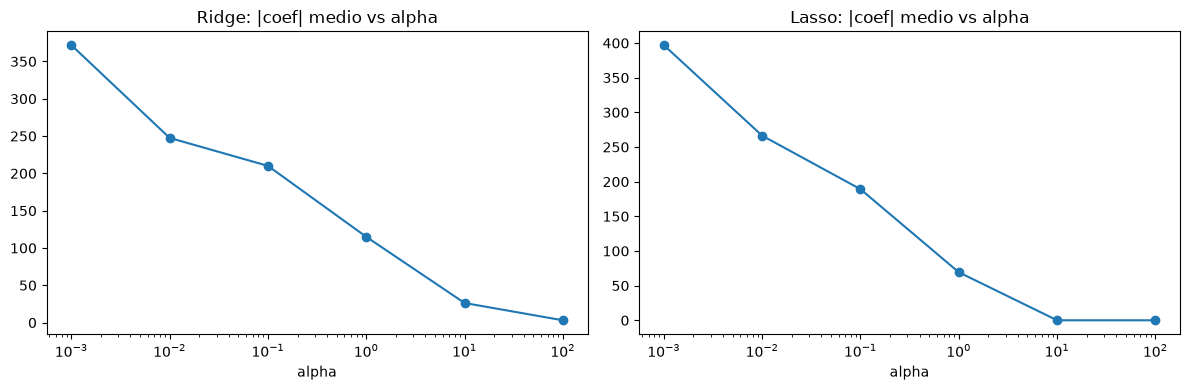

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, (nom, coefs) in enumerate([("Ridge", coef_ridge), ("Lasso", coef_lasso)]):
    ax[k].plot(alphas, np.array(coefs).mean(axis=1), marker="o")
    ax[k].set_xscale("log"); ax[k].set_title(f"{nom}: |coef| medio vs alpha")
    ax[k].set_xlabel("alpha")
plt.tight_layout(); plt.show()

**Interpretación** (keywords)

1. Mejor modelo → kNN (menor MAE) / Lasso (mayor R²); árbol el peor (R² negativo)
2. MAE pondera lineal los errores; RMSE penaliza más los errores grandes → un outlier puede cambiar el ranking
3. R² < 0 → el modelo predice PEOR que la media de y (residuos > varianza)
4. Más regularización → coeficientes más pequeños (Lasso: a 0), menor varianza, riesgo de subajuste (bias↑)
5. Errores grandes → outliers en y, ruido, features insuficientes, o distribución diferente
6. No → coeficiente grande = predictivo, no causal (falta experimentación/confounding)

**Cierre**

- [x] Iris explorado (tabla + gráfico de clases)
- [x] 7 clasificadores comparados (train/val/test, scaler solo con train)
- [x] Tabla de prueba + matrices de confusión (GNB, SVM, MLP) + análisis de errores
- [x] 8 modelos de regresión comparados (MAE/RMSE/R²) + residuos
- [x] Regularización Ridge/Lasso con alphas en validación